In [ ]:
import matplotlib.pyplot as plot
import pandas
import seaborn
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import auc, roc_curve
from sklearn.model_selection import StratifiedKFold, cross_val_score, train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.inspection import permutation_importance



In [6]:
# Load the cleaned dataset
heart_disease_dataset = pandas.read_csv('heart_disease_clean.csv')

# Define features and target using descriptive names
patient_features = heart_disease_dataset.drop('target', axis=1)
heart_disease_target = heart_disease_dataset['target']

# Split into training and testing sets (75/25 split)
training_features, testing_features, training_target, testing_target = train_test_split(
    patient_features, 
    heart_disease_target, 
    test_size=0.25, 
    random_state=42, 
    stratify=heart_disease_target
)

# Scale the features (Crucial for Logistic Regression and distance-based metrics)
standard_scaler = StandardScaler()
scaled_training_features = standard_scaler.fit_transform(training_features)
scaled_testing_features = standard_scaler.transform(testing_features)

print(f"Training set size: {scaled_training_features.shape[0]} instances")
print(f"Testing set size: {scaled_testing_features.shape[0]} instances")

Training set size: 227 instances
Testing set size: 76 instances


In [7]:

# 1. Initialize and train Logistic Regression
logistic_regression_model = LogisticRegression(random_state=42, max_iter=1000)
logistic_regression_model.fit(scaled_training_features, training_target)

# 2. Initialize and train Random Forest
random_forest_model = RandomForestClassifier(n_estimators=100, random_state=42)
random_forest_model.fit(scaled_training_features, training_target)

# 4. Initialize and train K-Nearest Neighbors
k_nearest_neighbors_model = KNeighborsClassifier(n_neighbors=5)
k_nearest_neighbors_model.fit(scaled_training_features, training_target)

,"n_neighbors n_neighbors: int, default=5Number of neighbors to use by default for :meth:`kneighbors` queries.",5
,"weights weights: {'uniform', 'distance'}, callable or None, default='uniform'Weight function used in prediction. Possible values:- 'uniform' : uniform weights. All points in each neighborhood are weighted equally.- 'distance' : weight points by the inverse of their distance. in this case, closer neighbors of a query point will have a greater influence than neighbors which are further away.- [callable] : a user-defined function which accepts an array of distances, and returns an array of the same shape containing the weights.Refer to the example entitled:ref:`sphx_glr_auto_examples_neighbors_plot_classification.py`showing the impact of the `weights` parameter on the decisionboundary.",'uniform'
,"algorithm algorithm: {'auto', 'ball_tree', 'kd_tree', 'brute'}, default='auto'Algorithm used to compute the nearest neighbors:- 'ball_tree' will use :class:`BallTree`- 'kd_tree' will use :class:`KDTree`- 'brute' will use a brute-force search.- 'auto' will attempt to decide the most appropriate algorithm based on the values passed to :meth:`fit` method.Note: fitting on sparse input will override the setting ofthis parameter, using brute force.",'auto'
,"leaf_size leaf_size: int, default=30Leaf size passed to BallTree or KDTree. This can affect thespeed of the construction and query, as well as the memoryrequired to store the tree. The optimal value depends on thenature of the problem.",30
,"p p: float, default=2Power parameter for the Minkowski metric. When p = 1, this is equivalentto using manhattan_distance (l1), and euclidean_distance (l2) for p = 2.For arbitrary p, minkowski_distance (l_p) is used. This parameter is expectedto be positive.",2
,"metric metric: str or callable, default='minkowski'Metric to use for distance computation. Default is ""minkowski"", whichresults in the standard Euclidean distance when p = 2. See thedocumentation of `scipy.spatial.distance<https://docs.scipy.org/doc/scipy/reference/spatial.distance.html>`_ andthe metrics listed in:class:`~sklearn.metrics.pairwise.distance_metrics` for valid metricvalues.If metric is ""precomputed"", X is assumed to be a distance matrix andmust be square during fit. X may be a :term:`sparse graph`, in whichcase only ""nonzero"" elements may be considered neighbors.If metric is a callable function, it takes two arrays representing 1Dvectors as inputs and must return one value indicating the distancebetween those vectors. This works for Scipy's metrics, but is lessefficient than passing the metric name as a string.",'minkowski'
,"metric_params metric_params: dict, default=NoneAdditional keyword arguments for the metric function.",None
,"n_jobs n_jobs: int, default=NoneThe number of parallel jobs to run for neighbors search.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details.Doesn't affect :meth:`fit` method.",None
Name,Type,Value
"classes_ classes_: array of shape (n_classes,)Class labels known to the classifier","ndarray[int64](2,)","[0,1]"
"effective_metric_ effective_metric_: str or callbleThe distance metric used. It will be same as the `metric` parameteror a synonym of it, e.g. 'euclidean' if the `metric` parameter set to'minkowski' and `p` parameter set to 2.",str,'eu...an'


In [ ]:
# Define Stratified K-Fold (5 folds)
stratified_k_fold = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

# Cross-Validation for Logistic Regression
cross_validation_scores_logistic_regression = cross_val_score(
    logistic_regression_model, scaled_training_features, training_target, cv=stratified_k_fold, scoring='roc_auc'
)
print(f"Logistic Regression Cross-Validation AUROC Mean: {cross_validation_scores_logistic_regression.mean():.4f} (+/- {cross_validation_scores_logistic_regression.std() * 2:.4f})")

# Cross-Validation for Random Forest
cross_validation_scores_random_forest = cross_val_score(
    random_forest_model, scaled_training_features, training_target, cv=stratified_k_fold, scoring='roc_auc'
)
print(f"Random Forest Cross-Validation AUROC Mean: {cross_validation_scores_random_forest.mean():.4f} (+/- {cross_validation_scores_random_forest.std() * 2:.4f})")

# Cross-Validation for K-Nearest Neighbors
cross_validation_scores_k_nearest_neighbors = cross_val_score(
    k_nearest_neighbors_model,
    scaled_training_features,
    training_target,
    cv=stratified_k_fold,
    scoring="roc_auc",
)
print(
    f"K-Nearest Neighbors Cross-Validation AUROC Mean: {cross_validation_scores_k_nearest_neighbors.mean():.4f} (+/- {cross_validation_scores_k_nearest_neighbors.std() * 2:.4f})"
)

Logistic Regression Cross-Validation AUROC Mean: 0.8417 (+/- 0.1129)
Random Forest Cross-Validation AUROC Mean: 0.8223 (+/- 0.1099)


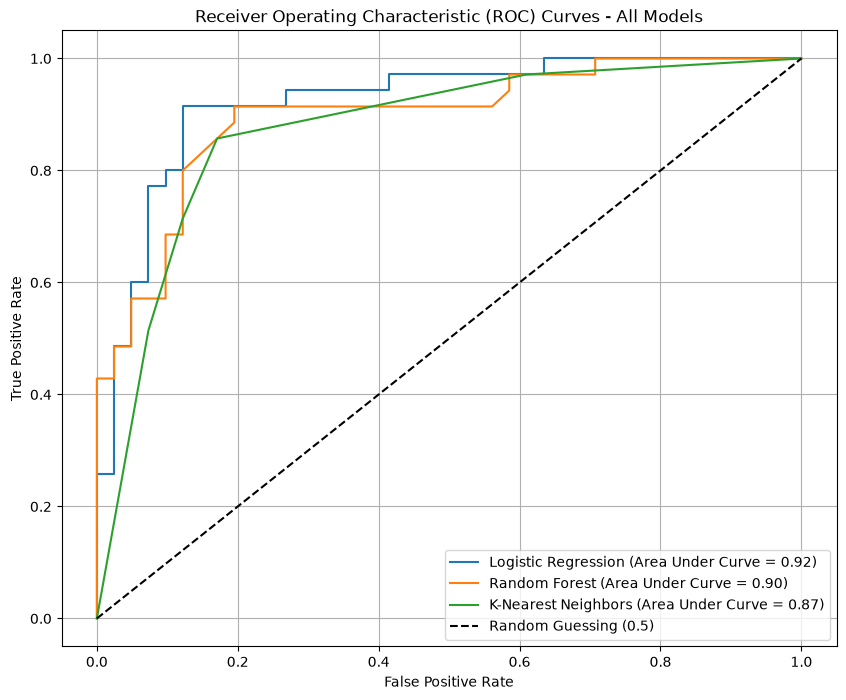

In [10]:
# Get probability predictions for the test set
logistic_regression_probability_predictions = logistic_regression_model.predict_proba(scaled_testing_features)[:, 1]
random_forest_probability_predictions = random_forest_model.predict_proba(scaled_testing_features)[:, 1]
k_nearest_neighbors_probability_predictions = k_nearest_neighbors_model.predict_proba(scaled_testing_features)[:, 1]

# Calculate ROC curves and Area Under the Curve for Logistic Regression
false_positive_rate_logistic_regression, true_positive_rate_logistic_regression, _ = (
    roc_curve(testing_target, logistic_regression_probability_predictions)
)
area_under_curve_logistic_regression = auc(
    false_positive_rate_logistic_regression, true_positive_rate_logistic_regression
)

# Calculate ROC curves and Area Under the Curve for Random Forest
false_positive_rate_random_forest, true_positive_rate_random_forest, _ = roc_curve(
    testing_target, random_forest_probability_predictions
)
area_under_curve_random_forest = auc(
    false_positive_rate_random_forest, true_positive_rate_random_forest
)

# Calculate ROC curves and Area Under the Curve for K-Nearest Neighbors
false_positive_rate_k_nearest_neighbors, true_positive_rate_k_nearest_neighbors, _ = (
    roc_curve(testing_target, k_nearest_neighbors_probability_predictions)
)
area_under_curve_k_nearest_neighbors = auc(
    false_positive_rate_k_nearest_neighbors, true_positive_rate_k_nearest_neighbors
)

# Plot ROC Curves for all models
plot.figure(figsize=(10, 8))

plot.plot(
    false_positive_rate_logistic_regression,
    true_positive_rate_logistic_regression,
    label=f"Logistic Regression (Area Under Curve = {area_under_curve_logistic_regression:.2f})",
)
plot.plot(
    false_positive_rate_random_forest,
    true_positive_rate_random_forest,
    label=f"Random Forest (Area Under Curve = {area_under_curve_random_forest:.2f})",
)
plot.plot(
    false_positive_rate_k_nearest_neighbors,
    true_positive_rate_k_nearest_neighbors,
    label=f"K-Nearest Neighbors (Area Under Curve = {area_under_curve_k_nearest_neighbors:.2f})",
)

plot.plot([0, 1], [0, 1], "k--", label="Random Guessing (0.5)")
plot.xlabel("False Positive Rate")
plot.ylabel("True Positive Rate")
plot.title("Receiver Operating Characteristic (ROC) Curves - All Models")
plot.legend(loc="lower right")
plot.grid(True)
plot.show()

In [ ]:
# Ensemble the models using a simple average of their predicted probabilities
ensemble_probability_predictions = (
    logistic_regression_probability_predictions +
    random_forest_probability_predictions +
    k_nearest_neighbors_probability_predictions
) / 3   
# Calculate ROC curves and Area Under the Curve for the ensemble model
false_positive_rate_ensemble, true_positive_rate_ensemble, _ = roc_curve(
    testing_target, ensemble_probability_predictions
)
area_under_curve_ensemble = auc(false_positive_rate_ensemble, true_positive_rate_ensemble)
